[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/beykyle/jitr/blob/main/examples/notebooks/total_and_reaction_xs.ipynb)

On Colab the first `import exfor_tools` downloads and unpacks the EXFOR database, which takes a few minutes.

In [1]:
# Google Colab setup: installs jitr and this notebook's extra dependencies.
# Does nothing when the notebook is run anywhere else.
import sys

if "google.colab" in sys.modules:
    import subprocess

    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", "jitr", "exfor-tools"],
        check=True,
    )

# Total and reaction cross sections across energies

The neutron total cross section and the proton reaction cross section of $^{58}$Ni, $^{90}$Zr and $^{208}$Pb up to 200 MeV, with the Koning-Delaroche global potential (KD03) and the KDUQ posterior, against data from [EXFOR](https://www-nds.iaea.org/exfor/).

Each target needs only one workspace: it solves every partial wave at every energy of a grid in one call. The theory is smooth, so a log-spaced grid of a few dozen energies stands in for the hundreds of energies at which the data were measured. Below a few MeV the neutron data resolve compound-nucleus resonances, which the optical model describes only on average.

In [2]:
import os

import exfor_tools
import jax  # noqa: F401 (used by %timeit below)
import matplotlib.pyplot as plt
import numpy as np
from exfor_tools.reaction import Reaction as ExforReaction
from exfor_tools.reaction import query_for_reaction

from jitr.optical_potentials import kduq
from jitr.reactions import Reaction
from jitr.utils import suggest_lmax, suggested_basis_size
from jitr.xs import elastic
from jitr.xs.coupled import Potential

# JITR_QUICK=1 runs a cut-down version of the notebook (fewer posterior samples) for CI
QUICK = os.environ.get("JITR_QUICK", "0") == "1"

Using database version X4-2024-12-31 located in: /home/kyle/db/exfor/unpack_exfor-2024/X4-2024-12-31


In [3]:
neutron, proton = (1, 0), (1, 1)
cases = [
    (neutron, (58, 28), "tot", r"$^{58}$Ni"),
    (neutron, (90, 40), "tot", r"$^{90}$Zr"),
    (neutron, (208, 82), "tot", r"$^{208}$Pb"),
    (proton, (58, 28), "non", r"$^{58}$Ni"),
    (proton, (90, 40), "non", r"$^{90}$Zr"),
    (proton, (208, 82), "non", r"$^{208}$Pb"),
]
E_min = {neutron: 1.0, proton: 8.0}
E_max = 200.0

## Data

Every EXFOR entry for the reaction is parsed on its own; the few that `exfor_tools` cannot parse are skipped.

In [4]:
def measurements(projectile, target, process):
    """Energies (MeV), cross sections and errors (mb) of every parsable entry."""
    reaction = ExforReaction(target=target, projectile=projectile, process=process)
    E, xs, err = [], [], []
    for entry in query_for_reaction(reaction, "XS"):
        try:
            parsed = exfor_tools.ExforEntry(
                entry=entry, reaction=reaction, quantity="XS", vocal=False
            )
        except Exception:
            continue
        for m in parsed.measurements:
            E.append(m.x)
            xs.append(1e3 * m.y)
            err.append(1e3 * m.statistical_err)
    E, xs, err = (np.concatenate(x) for x in (E, xs, err))
    keep = (E >= E_min[projectile]) & (E <= E_max)
    return E[keep], xs[keep], err[keep]


data = {(p, t): measurements(p, t, process) for p, t, process, _ in cases}
for (p, t), (E, _, _) in data.items():
    print(f"{p} + {t}: {E.size} data points")

(1, 0) + (58, 28): 31201 data points
(1, 0) + (90, 40): 1613 data points
(1, 0) + (208, 82): 9279 data points
(1, 1) + (58, 28): 16 data points
(1, 1) + (90, 40): 12 data points
(1, 1) + (208, 82): 12 data points


## One workspace per target

The mesh is the same at every energy, so the channel radius, basis size and maximum partial wave are chosen for the highest energy of the grid.

In [5]:
def workspace(projectile, target, n_energies=40):
    reaction = Reaction(target=target, projectile=projectile, process="El")
    kinematics = reaction.kinematics(np.geomspace(E_min[projectile], E_max, n_energies))
    a = 1.25 * target[0] ** (1 / 3) + 8.0  # fm
    nbasis = suggested_basis_size(kinematics.k.max() * a)
    lmax = suggest_lmax(kinematics.k, a)
    return reaction, elastic.Workspace(reaction, kinematics, a, lmax, nbasis)


workspaces = {(p, t): workspace(p, t) for p, t, _, _ in cases}

## KD03 and the KDUQ posterior

The potentials depend on energy. Evaluated with the workspace kinematics, a built-in potential returns its terms at every energy of the grid at once, as `(NE, N)` arrays. The first call of each workspace compiles; the posterior samples then reuse the compiled solver.

In [6]:
def potential(reaction, ws, model, params):
    # with the workspace kinematics, every term is (NE, N)
    with np.errstate(over="ignore"):  # a saturating sigmoid in KDUQ
        central, spin_orbit, coulomb = model(ws.r, reaction, ws.kinematics, *params)
    if not np.any(coulomb):
        coulomb = None
    return Potential(central=central, spin_orbit=spin_orbit, coulomb=coulomb)


def cross_section(projectile, target, params):
    reaction, ws = workspaces[(projectile, target)]
    xs = ws.xs(potential(reaction, ws, kduq.KDUQ(projectile), params))
    return np.asarray(xs.t if projectile == neutron else xs.rxn)

In [7]:
%%time
n_samples = 5 if QUICK else 50
rng = np.random.default_rng(13)
kd03, posterior = {}, {}
for p, t, _, _ in cases:
    kd03[(p, t)] = cross_section(p, t, kduq.get_kd03(p))
    samples = kduq.get_samples(p)
    draws = samples[rng.choice(len(samples), n_samples, replace=False)]
    posterior[(p, t)] = np.array([cross_section(p, t, s) for s in draws])

CPU times: user 4min 24s, sys: 26.7 s, total: 4min 51s
Wall time: 2min 50s


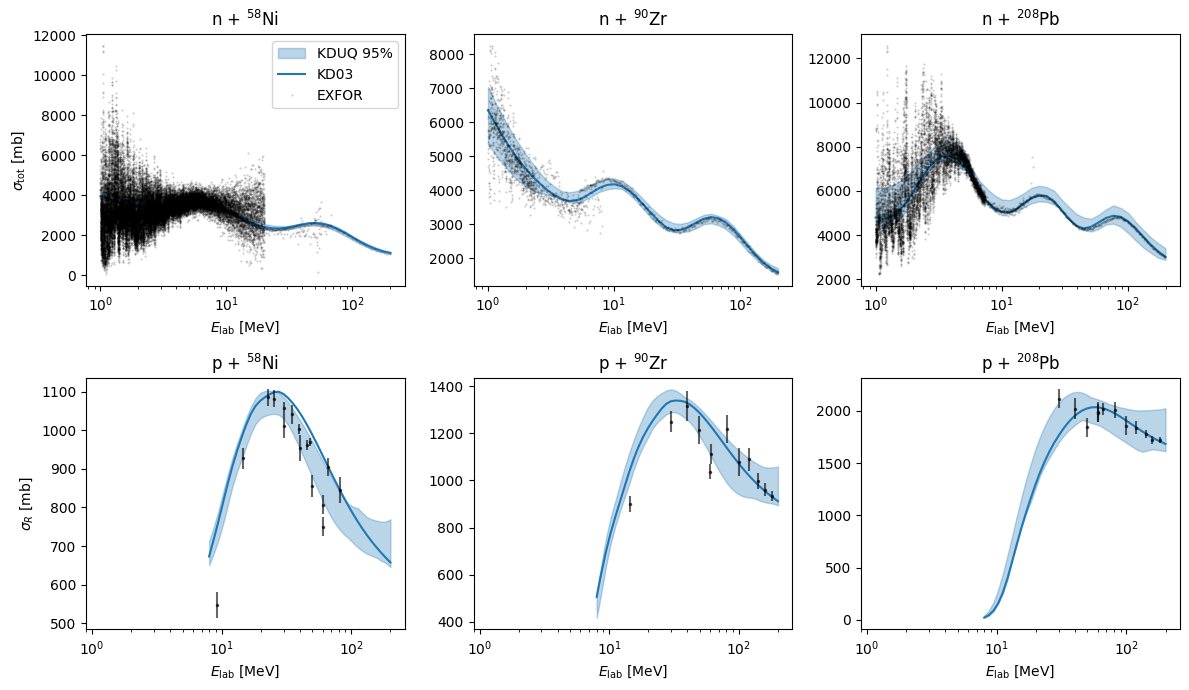

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(12, 7), sharex="row")
for ax, (p, t, _, label) in zip(axes.flat, cases, strict=True):
    _, ws = workspaces[(p, t)]
    E = ws.kinematics.Elab
    lo, hi = np.percentile(posterior[(p, t)], [2.5, 97.5], axis=0)
    ax.fill_between(E, lo, hi, color="C0", alpha=0.3, label="KDUQ 95%")
    ax.plot(E, kd03[(p, t)], "C0", label="KD03")
    E_data, xs, err = data[(p, t)]
    if E_data.size > 500:  # dense neutron data: points only
        ax.plot(E_data, xs, ".", color="k", ms=1, alpha=0.2, label="EXFOR")
    else:
        ax.errorbar(E_data, xs, err, fmt=".", color="k", ms=3, alpha=0.6, label="EXFOR")
    ax.set_xscale("log")
    projectile = "n" if p == neutron else "p"
    ax.set_title(f"{projectile} + {label}")
    ax.set_xlabel(r"$E_{\rm lab}$ [MeV]")
axes[0, 0].set_ylabel(r"$\sigma_{\rm tot}$ [mb]")
axes[1, 0].set_ylabel(r"$\sigma_{R}$ [mb]")
axes[0, 0].legend()
plt.tight_layout()
plt.show()

## How fast is a whole excitation function?

A full set of energies costs one call of the compiled workspace:

In [9]:
reaction, ws = workspaces[(neutron, (208, 82))]
p = potential(reaction, ws, kduq.KDUQ(neutron), kduq.get_kd03(neutron))
%timeit jax.block_until_ready(ws.xs(p))
print(f"{ws.kinematics.Elab.size} energies, {ws.blocks.J.size} J^pi blocks per energy")

729 ms ± 37.1 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)
40 energies, 113 J^pi blocks per energy
